In [103]:
# PART 1 — INSTALL
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (roc_auc_score, brier_score_loss, log_loss)
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone

In [104]:
# PART 2 — READ AND FILTER THE PUBLIC DATASET
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"  # Original public CSV.
df = pd.read_csv(URL)
df = df.loc[df["hotel"] == "City Hotel"].copy() # Keeps only City Hotel reservations.
df["nights"] = (df["stays_in_week_nights"] + df["stays_in_weekend_nights"]) #Calculates how many nights each reservation covers.
df = df.loc[(df["nights"] == 1) & (df["adults"] >= 1)].copy() # Keeps single-night reservations with at least one adult.

df["arrival"] = pd.to_datetime(  # Build a date for chronological model evaluation.
    df["arrival_date_year"].astype(str) + "-" + df["arrival_date_month"] + "-" + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",  # Parse year, full month name, and day.
)
print(f"One-night City Hotel records: {len(df):,}")  # Confirm sample size.


One-night City Hotel records: 13,227


# EDA

In [105]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

display(df.head(2)) # Display the first 3 rows

Dataset shape: (13227, 34)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,nights,arrival
40128,City Hotel,1,84,2015,July,28,10,0,1,2,...,NaN,0,Transient,63.75,0,0,Canceled,2015-06-30,1,2015-07-10
40135,City Hotel,0,71,2015,July,28,11,0,1,1,...,NaN,0,Transient,51.96,0,0,Check-Out,2015-07-12,1,2015-07-11


In [106]:
### Display column names, non-null counts, and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13227 entries, 40128 to 119237
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           13227 non-null  object        
 1   is_canceled                     13227 non-null  int64         
 2   lead_time                       13227 non-null  int64         
 3   arrival_date_year               13227 non-null  int64         
 4   arrival_date_month              13227 non-null  object        
 5   arrival_date_week_number        13227 non-null  int64         
 6   arrival_date_day_of_month       13227 non-null  int64         
 7   stays_in_weekend_nights         13227 non-null  int64         
 8   stays_in_week_nights            13227 non-null  int64         
 9   adults                          13227 non-null  int64         
 10  children                        13226 non-null  float64       
 11  ba

In [107]:
### Count numerical and categorical columns
print("Numerical columns:", df.select_dtypes(include="number").shape[1])
print("Categorical columns:", df.select_dtypes(include=["object", "category"]).shape[1])

Numerical columns: 21
Categorical columns: 12


## Check missing values

In [108]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_summary = pd.DataFrame({ "Missing Count": missing_count, "Missing Percentage": missing_percent})
display(missing_summary[missing_summary["Missing Count"] > 0])

,Missing Count,Missing Percentage
children,1,0.007560
agent,3298,24.933847
company,11477,86.769487


##### About missing values:
- children: 1 observation is missing. Since the number of children is generally zero for many bookings, filling this single value with 0 is a reasonable simplification. 
- agent: Missing values may indicate reservations made without a travel agent. So, we can create a binary variable indicating whether an agent ID was recorded.
- company: Almost 87% of the observations have no company ID. Rather than retaining the original company identifiers, we can create a binary variable indicating whether company information was recorded.

##### So, we define two binary vars below:
- has_agent
- has_company

In [109]:
### Handle missing values
# Fill the missing number of children with 0
df["children"] = df["children"].fillna(0)

# Create binary indicators for agent and company information
df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)

# Remove the original agent and company columns
df = df.drop(columns=["agent", "company"])

# Verify that no missing values remain
print(df.isnull().sum()[df.isnull().sum() > 0])


Series([], dtype: int64)


is_canceled
0    69.040599
1    30.959401
Name: proportion, dtype: float64


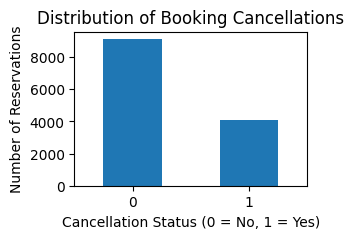

In [110]:
## Examine the target variable: is_canceled
print(df["is_canceled"].value_counts(normalize=True) * 100)
df["is_canceled"].value_counts().plot(kind="bar",figsize=(3, 2))
plt.title("Distribution of Booking Cancellations")
plt.xlabel("Cancellation Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Reservations")
plt.xticks(rotation=0)
plt.show()

## Feature Selection

In [111]:
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
is_canceled,13227.0,0.309594,0.0,0.0,0.0,1.0,1.0,0.462344
lead_time,13227.0,58.617903,0.0,2.0,18.0,75.0,629.0,93.030458
arrival_date_year,13227.0,2016.179028,2015.0,2016.0,2016.0,2017.0,2017.0,0.665068
arrival_date_week_number,13227.0,26.570122,1.0,15.5,27.0,38.0,53.0,13.834551
arrival_date_day_of_month,13227.0,16.034097,1.0,9.0,16.0,23.0,31.0,8.522072
stays_in_weekend_nights,13227.0,0.213654,0.0,0.0,0.0,0.0,1.0,0.409901
stays_in_week_nights,13227.0,0.786346,0.0,1.0,1.0,1.0,1.0,0.409901
adults,13227.0,1.676193,1.0,1.0,2.0,2.0,4.0,0.552829
children,13227.0,0.092538,0.0,0.0,0.0,0.0,3.0,0.375486
babies,13227.0,0.006577,0.0,0.0,0.0,0.0,2.0,0.083596


In [112]:
display(df.describe(include=["object", "category"]).T)

,count,unique,top,freq
hotel,13227,1,City Hotel,13227
arrival_date_month,13227,12,August,1467
meal,13227,4,BB,9993
country,13227,111,PRT,6752
market_segment,13227,8,Online TA,6287
distribution_channel,13227,5,TA/TO,9215
reserved_room_type,13227,7,A,10892
assigned_room_type,13227,8,A,9487
deposit_type,13227,3,No Deposit,12051
customer_type,13227,4,Transient,10443


#### Create calendar features

In [113]:
# Create a datetime column for the arrival date
df["arrival_date"] = pd.to_datetime(df["arrival_date_year"].astype(str) + "-" + df["arrival_date_month"] + "-" + 
                                    df["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")

# Extract numerical month
df["arrival_month_num"] = df["arrival_date"].dt.month

# Extract day of week (Monday = 0, Sunday = 6)
df["arrival_day_of_week"] = df["arrival_date"].dt.dayofweek

# Check the new features
display(df[["arrival_date", "arrival_month_num","arrival_day_of_week"]].head(3))

,arrival_date,arrival_month_num,arrival_day_of_week
40128,2015-07-10,7,4
40135,2015-07-11,7,5
40136,2015-07-11,7,5


##### I use the following features and will explain why did not consider others vars in Readme file

In [114]:
# Numerical features
numerical_features = ["lead_time", "adults", "children", "babies", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "has_agent", "has_company", "arrival_month_num", "arrival_day_of_week"]

# Categorical features
categorical_features = ["market_segment", "distribution_channel", "reserved_room_type"]

# Combine all selected features
selected_features = numerical_features + categorical_features

# Create feature matrix X
X = df[selected_features].copy()

# Create target variable y
y = df["is_canceled"].copy()

# Verify dimensions
print("X shape:", X.shape)
print("y shape:", y.shape)

# Preview selected features
display(X.head(3))


X shape: (13227, 14)
y shape: (13227,)


,lead_time,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,has_agent,has_company,arrival_month_num,arrival_day_of_week,market_segment,distribution_channel,reserved_room_type
40128,84,2,0.0,0,0,0,0,1,0,7,4,Groups,TA/TO,A
40135,71,1,0.0,0,0,0,0,1,0,7,5,Online TA,TA/TO,A
40136,3,2,0.0,0,0,0,0,1,0,7,5,Offline TA/TO,TA/TO,A


# Create Training and Testing Sets

In [115]:
df = df.sort_values("arrival_date").reset_index(drop=True)

# Get all unique arrival dates as we don't want reservations from the same day divided between training and testing.
unique_dates = (df["arrival_date"].drop_duplicates().sort_values().reset_index(drop=True))

# Define the cutoff dates: 68% for training - 12% for validation - 20% for test
train_cutoff = unique_dates.iloc[int(len(unique_dates) * 0.68)]
test_cutoff = unique_dates.iloc[int(len(unique_dates) * 0.80)]

print(train_cutoff)
print(test_cutoff)

2016-12-26 00:00:00
2017-03-29 00:00:00


In [116]:
# Create masks for training, validation, and testing observations
train_mask = df["arrival_date"] < train_cutoff
val_mask = ((df["arrival_date"] >= train_cutoff) & (df["arrival_date"] < test_cutoff))
test_mask = df["arrival_date"] >= test_cutoff

print("Training dates:", df.loc[train_mask, "arrival_date"].min(), "to", df.loc[train_mask, "arrival_date"].max())
print("Validation dates:", df.loc[val_mask, "arrival_date"].min(), "to", df.loc[val_mask, "arrival_date"].max())
print("Testing dates:", df.loc[test_mask, "arrival_date"].min(), "to", df.loc[test_mask, "arrival_date"].max())

Training dates: 2015-07-06 00:00:00 to 2016-12-25 00:00:00
Validation dates: 2016-12-26 00:00:00 to 2017-03-28 00:00:00
Testing dates: 2017-03-29 00:00:00 to 2017-08-31 00:00:00


In [117]:
# Create feature sets
X_train = df.loc[train_mask, selected_features].copy()
X_val = df.loc[val_mask, selected_features].copy()
X_test = df.loc[test_mask, selected_features].copy()

# Create target sets
y_train = df.loc[train_mask, "is_canceled"].copy()
y_val = df.loc[val_mask, "is_canceled"].copy()
y_test = df.loc[test_mask, "is_canceled"].copy()

# Display dataset sizes
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (8807, 14)
X_val: (1505, 14)
X_test: (2915, 14)


In [118]:
# Compare cancellation rates
print("Training cancellation rate:", round(y_train.mean() * 100, 2), "%")
print("Validation cancellation rate:", round(y_val.mean() * 100, 2), "%")
print("Testing cancellation rate:", round(y_test.mean() * 100, 2), "%")

Training cancellation rate: 30.28 %
Validation cancellation rate: 28.24 %
Testing cancellation rate: 34.41 %


##### nearly the same

# Preprocessing

##### As we took care of missing values previously, preprocessing is simple here

In [119]:
### Function to create a complete ML pipeline
def make_pipeline(model):
    # Define preprocessing transformations
    preprocessor = ColumnTransformer(transformers=[("num", StandardScaler(), numerical_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])
    # Combine preprocessing with the ML algorithm
    pipeline = Pipeline(steps=[("preprocess", preprocessor),("model", model)])
    return pipeline

### Define models

In [120]:
models = {
    "Historical rate": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=120, min_samples_leaf=10, random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=180, learning_rate=0.05, num_leaves=15, random_state=42, verbosity=-1, n_jobs=-1)
}

### Calculate metrics from true labels and cancellation probabilities

In [121]:
def evaluate_model(y_true, probabilities):
    return {"ROC-AUC": roc_auc_score(y_true, probabilities), "Brier": brier_score_loss(y_true, probabilities),
        "Log Loss": log_loss(y_true, probabilities)}

In [122]:

# Store fitted models and their results
fitted_models = {}
initial_results = []

# Train and evaluate each model
for name, algorithm in models.items():
    # Create a fresh preprocessing + ML pipeline
    pipeline = make_pipeline(algorithm)
    pipeline.fit(X_train, y_train)
    val_probabilities = pipeline.predict_proba(X_val)[:, 1]
    scores = evaluate_model(y_val, val_probabilities)
    fitted_models[name] = pipeline
    initial_results.append({"Model": name, **scores})

# Convert results to a comparison table
initial_comparison = pd.DataFrame(initial_results)
# Sort by Brier score
initial_comparison = initial_comparison.sort_values("Brier")
display(initial_comparison.round(4))


,Model,ROC-AUC,Brier,Log Loss
1,Logistic Regression,0.7467,0.1822,0.5371
2,Random Forest,0.7140,0.1836,0.5438
0,Historical rate,0.5000,0.2031,0.5962
3,LightGBM,0.6782,0.2103,0.6154


# Hyperparameter Tuning

In [123]:

from sklearn.model_selection import ParameterGrid
from sklearn.base import clone

# Define hyperparameter combinations
param_grids = {"Logistic Regression": {"model__C": [0.1, 1, 10, 100]},
"Random Forest": {"model__max_depth": [8, 15, None], "model__min_samples_leaf": [2, 5, 10], "model__max_features": ["sqrt", 0.7]},
"LightGBM": {"model__n_estimators": [150, 300], "model__learning_rate": [0.05, 0.1],
        "model__num_leaves": [15, 30],"model__min_child_samples": [20, 60]}}

# Save best models and all tuning results
tuned_models = {}
tuning_results = []

# Tune each ML algorithm
for name, grid in param_grids.items():
    best_brier = float("inf")
    best_model = None
    best_params = None
    for params in ParameterGrid(grid):
        candidate = make_pipeline(clone(models[name]))
        candidate.set_params(**params)
        candidate.fit(X_train, y_train)
        probabilities = candidate.predict_proba(X_val)[:, 1] # Predict on validation

        brier = brier_score_loss(y_val, probabilities)
        tuning_results.append({"Model": name, "Parameters": str(params), "Brier": brier})

        if brier < best_brier:
            best_brier = brier
            best_model = candidate
            best_params = params

    tuned_models[name] = best_model

    print(f"\n{name}")
    print("Best parameters:", best_params)
    print("Validation Brier:", round(best_brier, 4))




Logistic Regression
Best parameters: {'model__C': 0.1}
Validation Brier: 0.1805

Random Forest
Best parameters: {'model__max_depth': 15, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2}
Validation Brier: 0.181

LightGBM
Best parameters: {'model__learning_rate': 0.05, 'model__min_child_samples': 60, 'model__n_estimators': 150, 'model__num_leaves': 15}
Validation Brier: 0.207


### Compare the Tuned Models on Validation

In [124]:
validation_models = {"Historical rate": fitted_models["Historical rate"],**tuned_models}
validation_results = []
for name, model in validation_models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    scores = evaluate_model(y_val, probabilities)
    validation_results.append({"Model": name, **scores})

validation_comparison = pd.DataFrame(validation_results)
validation_comparison = (validation_comparison.sort_values("Brier").reset_index(drop=True))

display(validation_comparison.round(4))

,Model,ROC-AUC,Brier,Log Loss
0,Logistic Regression,0.7465,0.1805,0.5330
1,Random Forest,0.7248,0.1810,0.5331
2,Historical rate,0.5000,0.2031,0.5962
3,LightGBM,0.6464,0.2070,0.6117


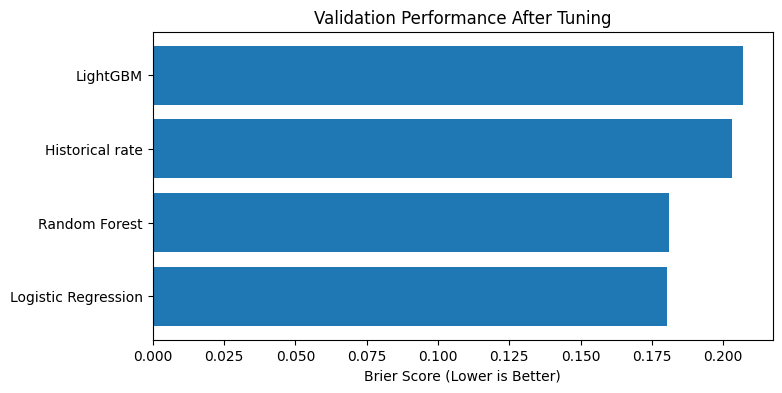

In [125]:
# Plot validation Brier scores
plt.figure(figsize=(8, 4))
plt.barh(validation_comparison["Model"],validation_comparison["Brier"])

plt.xlabel("Brier Score (Lower is Better)")
plt.title("Validation Performance After Tuning")
plt.show()

### Check Probability Calibration

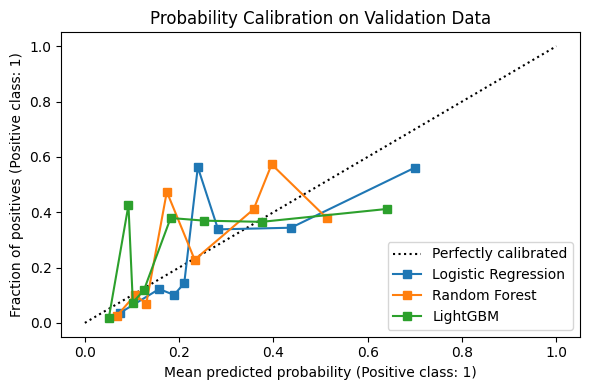

In [126]:

from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(6, 4))

for name, model in tuned_models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    CalibrationDisplay.from_predictions(y_val, probabilities, n_bins=8, strategy="quantile", name=name, ax=ax)

plt.title("Probability Calibration on Validation Data")
plt.tight_layout()
plt.show()


### Select The Best Model

In [127]:
best_name = validation_comparison.iloc[0]["Model"]

best_validation_model = validation_models[best_name]
print("Selected model:", best_name)
print("Validation Brier:", round(validation_comparison.iloc[0]["Brier"], 4))

Selected model: Logistic Regression
Validation Brier: 0.1805


### Retrain with Train + Validation Data

In [128]:
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

final_model = clone(best_validation_model)
final_model.fit(X_trainval, y_trainval)

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_scores = evaluate_model(y_test, test_probabilities)


### Final Test Performance

In [129]:
print("Final model:", best_name)

for metric, score in test_scores.items():
    print(f"{metric}: {score:.4f}")

# Compare predicted and actual cancellation rates
print("\nActual cancellation rate:", f"{y_test.mean():.2%}")
print("Mean predicted cancellation probability:", f"{test_probabilities.mean():.2%}")

Final model: Logistic Regression
ROC-AUC: 0.7612
Brier: 0.1802
Log Loss: 0.5349

Actual cancellation rate: 34.41%
Mean predicted cancellation probability: 35.17%


In [130]:
baseline = DummyClassifier(strategy="prior")
baseline.fit(X_trainval, y_trainval)
# Predict using the baseline
baseline_probs = baseline.predict_proba(X_test)[:, 1]
# Compare both models
test_comparison = pd.DataFrame([{"Model": "Historical Rate", **evaluate_model(y_test, baseline_probs)},
    {"Model": best_name,**test_scores}])
display(test_comparison.round(4))

,Model,ROC-AUC,Brier,Log Loss
0,Historical Rate,0.5000,0.2276,0.6482
1,Logistic Regression,0.7612,0.1802,0.5349


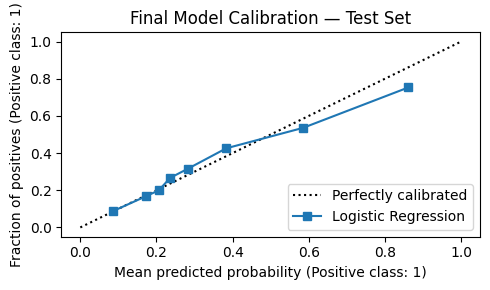

In [131]:
fig, ax = plt.subplots(figsize=(5, 3))
CalibrationDisplay.from_predictions(y_test, test_probabilities, n_bins=8, strategy="quantile", name=best_name, ax=ax)
plt.title("Final Model Calibration — Test Set")
plt.tight_layout()
plt.show()

# Optimization

### Understanding the Average Number of Booking & Price

In [145]:
daily_bookings = df.groupby("arrival_date").size()
print("Average daily bookings:", round(daily_bookings.mean(), 2))
print("Average ADR:", df["adr"].mean())

Average daily bookings: 17.05
Average ADR: 106.00655477432524


### Define parameters:

In [132]:
ROOMS = 17 # Hotel capacity
MAX_EXTRA = 15#5 # Maximum number of additional reservations
FIXED_EXTRA = 5#3 # Fixed overbooking strategy
ROOM_PRICE = 125 # Revenue per occupied room
BUMP_COST = 350 # Penalty for each guest exceeding hotel capacity

In [133]:
# Select test reservations
optimization_data = df.loc[test_mask, ["arrival_date", "lead_time", "is_canceled"]].copy()

# Add predicted cancellation probabilities
optimization_data["p_cancel"] = np.asarray(test_probabilities, dtype=float)

# Sort by arrival date and booking lead time
optimization_data = optimization_data.sort_values(["arrival_date", "lead_time"], ascending=[True, False])

# Calculate historical cancellation rate using development data
historical_rate = pd.concat([y_train, y_val]).mean()

print("Historical cancellation rate:", round(historical_rate, 4))

display(optimization_data.head(3))


Historical cancellation rate: 0.2998


,arrival_date,lead_time,is_canceled,p_cancel
10321,2017-03-29,82,0,0.331185
10326,2017-03-29,58,0,0.305380
10328,2017-03-29,56,0,0.271779


### Expected Profit Function

In [134]:
def expected_profit(cancel_probs, extra):
    n_accept = ROOMS + extra
    # Cancellation probabilities of accepted reservations
    p = np.asarray(cancel_probs[:n_accept], dtype=float)
    # Ensure enough reservations are available
    if len(p) != n_accept:
        raise ValueError("Not enough reservations")
    # Initialize arrival-count probability distribution
    arrival_dist = np.array([1.0])
    # Calculate distribution of the number of arrivals
    for cancel_p in p:
        arrival_dist = np.convolve(arrival_dist, [cancel_p, 1 - cancel_p])
    # All possible numbers of arriving guests
    arrivals = np.arange(len(arrival_dist))
    # Revenue from occupied rooms
    revenue = ROOM_PRICE * np.minimum(arrivals, ROOMS)
    # Cost of guests exceeding capacity
    penalty = BUMP_COST * np.maximum(arrivals - ROOMS, 0)
    # Expected profit across all possible outcomes
    profit = np.sum(arrival_dist * (revenue - penalty))
    return float(profit)


### Find the Optimal Number of Extra Bookings

In [135]:
def optimize_extra(cancel_probs):
    # Calculate expected profit for every possible decision
    profits = [expected_profit(cancel_probs, extra) for extra in range(MAX_EXTRA + 1)]
    best_extra = int(np.argmax(profits))
    return best_extra

### Apply Four Strategies

In [136]:
results = []

# Process one arrival date at a time
for date, group in optimization_data.groupby("arrival_date"):

    # Put earlier bookings first
    group = group.sort_values("lead_time", ascending=False)

    # Keep dates with at least 15 reservation candidates
    if len(group) < ROOMS + MAX_EXTRA:
        continue

    # Individual ML cancellation probabilities
    p_ml = group["p_cancel"].to_numpy()

    # Historical cancellation probability for every customer
    p_historical = np.full(len(group), historical_rate)

    # Define the four overbooking policies
    policies = {
        "No Overbooking": 0,
        "Fixed +3": FIXED_EXTRA,
        "Historical Rate": optimize_extra(p_historical),
        "ML Optimization": optimize_extra(p_ml)
    }

    # Evaluate every policy
    for policy_name, extra in policies.items():
        accepted = group.iloc[:ROOMS + extra]
        actual_arrivals = int((accepted["is_canceled"] == 0).sum())
        served = min(actual_arrivals, ROOMS)
        bumped = max(actual_arrivals - ROOMS, 0)
        realized_profit = (ROOM_PRICE * served- BUMP_COST * bumped)

        predicted_profit = expected_profit(p_ml, extra)

        # Save results
        results.append({"Date": date, "Policy": policy_name, "Extra Bookings": extra, "Accepted": len(accepted), 
            "Arrivals": actual_arrivals, "Served": served, "Bumped": bumped, "Occupancy": served / ROOMS,
            "Expected Profit": predicted_profit, "Realized Profit": realized_profit})

optimization_results = pd.DataFrame(results)

print("Eligible dates:", optimization_results["Date"].nunique())

display(optimization_results.head(12))


Eligible dates: 20


,Date,Policy,Extra Bookings,Accepted,Arrivals,Served,Bumped,Occupancy,Expected Profit,Realized Profit
0,2017-04-29,No Overbooking,0,17,10,10,0,0.588235,1350.657015,1250
1,2017-04-29,Fixed +3,5,22,14,14,0,0.823529,1770.226382,1750
2,2017-04-29,Historical Rate,5,22,14,14,0,0.823529,1770.226382,1750
3,2017-04-29,ML Optimization,6,23,14,14,0,0.823529,1799.674358,1750
4,2017-05-09,No Overbooking,0,17,2,2,0,0.117647,561.306947,250
5,2017-05-09,Fixed +3,5,22,4,4,0,0.235294,955.630704,500
6,2017-05-09,Historical Rate,5,22,4,4,0,0.235294,955.630704,500
7,2017-05-09,ML Optimization,15,32,4,4,0,0.235294,1308.180351,500
8,2017-05-10,No Overbooking,0,17,11,11,0,0.647059,1408.501166,1375
9,2017-05-10,Fixed +3,5,22,11,11,0,0.647059,1767.313989,1375


### Compare the Four Policies

In [137]:

# Calculate summary statistics for each policy
summary = optimization_results.groupby("Policy").agg(
    Days=("Date", "nunique"),
    Avg_Extra_Bookings=("Extra Bookings", "mean"),
    Avg_Occupancy=("Occupancy", "mean"),
    Avg_Bumped_Guests=("Bumped", "mean"),
    Avg_Expected_Profit=("Expected Profit", "mean"),
    Avg_Realized_Profit=("Realized Profit", "mean")
)
summary["Avg_Occupancy"] *= 100
summary = summary.sort_values("Avg_Realized_Profit", ascending=False)
display(summary.round(2))

,Days,Avg_Extra_Bookings,Avg_Occupancy,Avg_Bumped_Guests,Avg_Expected_Profit,Avg_Realized_Profit
Policy,,,,,,
ML Optimization,20,9.4,70.29,0.90,1734.06,1178.75
Fixed +3,20,5.0,58.24,0.45,1440.26,1080.00
Historical Rate,20,5.0,58.24,0.45,1440.26,1080.00
No Overbooking,20,0.0,44.12,0.00,1068.28,937.50


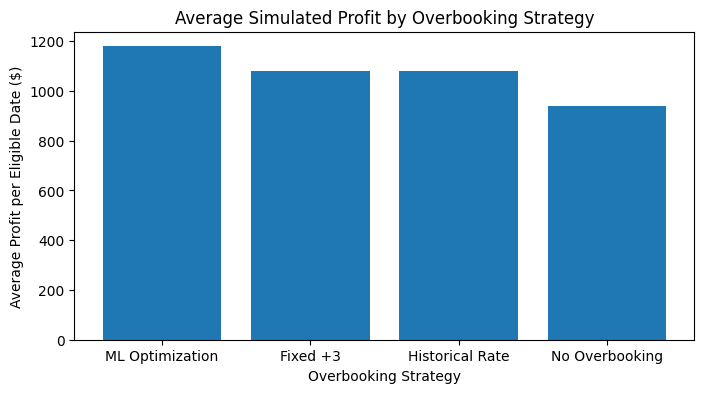

In [138]:

plt.figure(figsize=(8, 4))
plt.bar(summary.index,summary["Avg_Realized_Profit"])
plt.title("Average Simulated Profit by Overbooking Strategy")
plt.ylabel("Average Profit per Eligible Date ($)")
plt.xlabel("Overbooking Strategy")
plt.show()


### Quantify the value of machine learning

In [139]:
profit_comparison = optimization_results.pivot(index="Date", columns="Policy", values="Realized Profit")
profit_difference = (profit_comparison["ML Optimization"] - profit_comparison["Historical Rate"])
print("Average daily profit difference:", round(profit_difference.mean(), 2))
print("Total profit difference:", round(profit_difference.sum(), 2))
print("Days ML performed better:", (profit_difference > 0).sum())
print("Days both policies performed equally:", (profit_difference == 0).sum())
print("Days historical-rate optimization performed better:", (profit_difference < 0).sum())


Average daily profit difference: 98.75
Total profit difference: 1975
Days ML performed better: 12
Days both policies performed equally: 7
Days historical-rate optimization performed better: 1


,arrival_date,adr,is_canceled
0,2015-07-06,66.13,0
1,2015-07-09,68.00,1
2,2015-07-09,76.50,1
3,2015-07-09,76.50,1
4,2015-07-10,63.75,1
5,2015-07-11,51.96,0
6,2015-07-11,75.00,0
7,2015-07-11,104.00,0
8,2015-07-11,51.96,0
9,2015-07-13,63.75,0


Average ADR: 106.00655477432524
